# GJ 876: haze chemistry on the runaway points

In the main sweep, the seven hottest GJ 876 points (1079-1400 W/m2) had **no photochemical steady state**: with Photochem's haze-forming reactions removed (`remove_reaction_particles=True`), C4H4 piled up without bound. Here the same coupled climate-photochemistry loop is rerun on those points with the haze reactions **kept** (`haze=True` in `sweeplib.run_point`).

Haze network: `C2H + C4H2 -> HCaer1 + H`, `H2CN + HCN -> HCaer2`, `C4H + HCCCN -> HCaer3`. Particles use Photochem's default radius (1e-4 cm) unless stated.

**Caveat:** haze acts in the photochemistry only (a carbon sink and a settling species). The climate model ignores haze optical effects (no anti-greenhouse, no UV-shielding feedback on temperature).

In [1]:
import json, glob, csv, os
import numpy as np, matplotlib.pyplot as plt
def load(d):
    return {round(m['S_Wm2'],1): m for m in (json.load(open(p)) for p in glob.glob(f'{d}/GJ876_S*.json'))}
haze = load('sweep_results_haze'); S = sorted(haze)
nohaze = {s: m for s, m in load('sweep_results').items() if s in haze}
diag = {round(float(r['S_Wm2']),1): r for r in csv.DictReader(open('haze_diagnostics.csv')) if float(r['particle_radius_cm']) == 1e-4}
print(f"{'S':>7} {'no haze':<28} {'pCO2':>9} {'T':>6} | {'haze: stop':<36} {'pCO2':>9} {'T':>6} {'CO':>8} {'CH4':>8} {'haze C/in':>10}")
for s in S:
    a,b=nohaze[s],haze[s]
    print(f"{s:7.1f} {a['photochem_stop']:<28} {a['pCO2_bar']:9.2e} {a['T_surf_K']:6.1f} | {b['photochem_stop']:<36} {b['pCO2_bar']:9.2e} {b['T_surf_K']:6.1f} {b['vmr']['CO']:8.1e} {b['vmr']['CH4']:8.1e} {float(diag[s]['haze_carbon_over_reduced_carbon_input']):10.2f}")
print("\nhaze C/in = carbon locked in haze / carbon supplied as CH4+CO+HCN+CH3CN surface fluxes (can exceed 1: CO2, held at fixed pressure, also supplies carbon)")

      S no haze                           pCO2      T | haze: stop                                pCO2      T       CO      CH4  haze C/in
 1079.2 runaway: C4H4 accumulating    2.28e-03  289.7 | composition steady over last decade   2.47e-03  288.2  2.8e-02  3.5e-05       0.00
 1102.1 runaway: C4H4 accumulating    1.36e-03  290.0 | composition steady over last decade   1.54e-03  288.4  2.5e-02  3.0e-05       0.32
 1125.0 runaway: C4H4 accumulating    1.40e-03  293.4 | composition steady over last decade   8.94e-04  288.1  1.8e-02  2.2e-05       0.65
 1193.8 runaway: C4H4 accumulating    1.93e-04  292.6 | composition steady over last decade   1.74e-04  288.3  6.1e-03  1.0e-05       1.21
 1262.5 runaway: C4H4 accumulating    1.66e-05  291.5 | photochem criterion                   2.21e-05  287.9  2.4e-04  3.7e-06       1.35
 1331.2 runaway: C4H4 accumulating    1.00e-05  298.0 | composition steady over last decade   1.00e-05  294.1  9.2e-05  4.5e-06       1.19
 1400.0 runaway: C4H4 accum

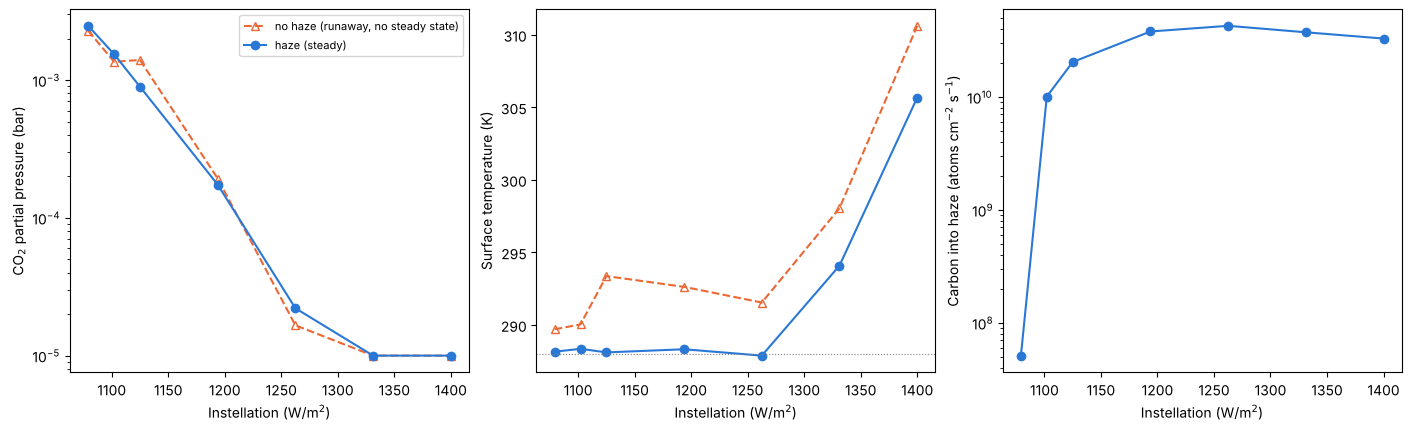

In [2]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4.2), constrained_layout=True)
c_n, c_h = '#eb6834', '#2a78d6'
for a, key, lab, log in [(ax[0],'pCO2_bar','CO$_2$ partial pressure (bar)',True),(ax[1],'T_surf_K','Surface temperature (K)',False)]:
    a.plot(S,[nohaze[s][key] for s in S],'^--',color=c_n,mfc='none',label='no haze (runaway, no steady state)')
    a.plot(S,[haze[s][key] for s in S],'o-',color=c_h,label='haze (steady)')
    a.set_xlabel('Instellation (W/m$^2$)'); a.set_ylabel(lab)
    if log: a.set_yscale('log')
ax[1].axhline(288,color='gray',lw=.8,ls=':'); ax[0].legend(fontsize=8)
ax[2].plot(S,[float(diag[s]['haze_carbon_atoms_cm-2_s-1']) for s in S],'o-',color=c_h)
ax[2].set_yscale('log'); ax[2].set_xlabel('Instellation (W/m$^2$)'); ax[2].set_ylabel('Carbon into haze (atoms cm$^{-2}$ s$^{-1}$)')
plt.show()

In [3]:
print('S   ', '  '.join(f'{s:8.1f}' for s in S))
for k in ['CO2','CO','O2','H2O','CH4','H2']:
    print(k.ljust(4), '  '.join(f"{haze[s]['vmr'][k]:.2e}" for s in S))

S      1079.2    1102.1    1125.0    1193.8    1262.5    1331.2    1400.0
CO2  2.37e-03  1.48e-03  8.66e-04  1.71e-04  2.18e-05  9.83e-06  9.71e-06
CO   2.81e-02  2.51e-02  1.85e-02  6.06e-03  2.39e-04  9.23e-05  8.69e-05
O2   1.15e-15  9.06e-18  4.34e-18  1.02e-17  5.21e-17  2.85e-17  1.74e-17
H2O  8.81e-03  8.76e-03  8.64e-03  8.40e-03  8.12e-03  1.27e-02  2.43e-02
CH4  3.50e-05  2.97e-05  2.24e-05  1.05e-05  3.68e-06  4.55e-06  5.73e-06
H2   4.17e-03  3.91e-03  3.88e-03  3.98e-03  4.17e-03  4.22e-03  4.25e-03


In [4]:
# particle-radius sensitivity (1e-5 cm instead of the default 1e-4 cm), if those runs are present
if os.path.isdir('sweep_results_haze_r1e-5'):
    r5 = load('sweep_results_haze_r1e-5')
    for s in sorted(r5):
        for lab, m in [('radius 1e-4 cm', haze[s]), ('radius 1e-5 cm', r5[s])]:
            print(f"S={s} {lab}: pCO2 {m['pCO2_bar']:.3e} bar, T {m['T_surf_K']:.2f} K, CO {m['vmr']['CO']:.2e}, CH4 {m['vmr']['CH4']:.2e}, steady={m['photochem_steady']}")

S=1125.0 radius 1e-4 cm: pCO2 8.944e-04 bar, T 288.11 K, CO 1.85e-02, CH4 2.24e-05, steady=True
S=1125.0 radius 1e-5 cm: pCO2 9.660e-04 bar, T 288.35 K, CO 1.96e-02, CH4 2.16e-05, steady=True
S=1193.8 radius 1e-4 cm: pCO2 1.738e-04 bar, T 288.33 K, CO 6.06e-03, CH4 1.05e-05, steady=True
S=1193.8 radius 1e-5 cm: pCO2 1.657e-04 bar, T 288.07 K, CO 6.37e-03, CH4 1.01e-05, steady=True
